# 12b · Synchronization and data-quality figures

Plot mapping status, timestamp coverage and data availability.


In [1]:
import sys
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / 'helpers/project_config.py').is_file())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from helpers.project_config import load_project_config

CONFIG = load_project_config(PROJECT_ROOT / 'config.json')
PROJECT_NAME = CONFIG.project
PREPROCESSED_ROOT = CONFIG.path('paths', 'preprocessed_data_root')
COVERAGE_CACHE = PROJECT_ROOT / '.cache' / 'sync_quality' / 'coverage_modules.json'
OUTPUT_DIR = CONFIG.path('paths', 'figures_cache_root')
OVERWRITE = True
FORCE_REBUILD_COVERAGE = False
from helpers.sync_quality import report, data_quality
from helpers.sync_quality.report import IDENTITY
QC_TABLE_PATHS = {key: CONFIG.path('files', key)
                  for key in CONFIG.values['files'] if key.endswith('_alignment_csv')}
_, QC_TABLES = report.load_qc_tables(QC_TABLE_PATHS)


In [2]:
plot_colors = {"usable": "#009E73", "review": "#E69F00", "unusable": "#B7B7B7",
               "supported": "#0072B2", "extrapolated": "#E69F00", "missing": "#B7B7B7"}
plot_style = {"font.family": "DejaVu Sans", "font.size": 16, "axes.titlesize": 20,
              "axes.labelsize": 16, "xtick.labelsize": 16, "ytick.labelsize": 16,
              "legend.fontsize": 16, "axes.spines.top": False, "axes.spines.right": False,
              "axes.linewidth": 1.5, "svg.fonttype": "none", "savefig.facecolor": "white",
              "boxplot.boxprops.linewidth": 2, "boxplot.whiskerprops.linewidth": 2,
              "boxplot.capprops.linewidth": 2, "boxplot.medianprops.linewidth": 2}

def plot_panel(ax, title, xlabel="", ylabel="", grid="y"):
    ax.set_title(title, loc="left", pad=11, fontweight="bold")
    ax.set(xlabel=xlabel, ylabel=ylabel)
    ax.set_axisbelow(True)
    ax.grid(axis=grid, color="#E8E8E8", linewidth=.6)

def plot_overview(records, coverage, quality):
    names = {'et_lsl': 'ET raw → LSL', 'eyeball_et': 'Eyeball → ET raw',
             'eyeball_lsl': 'Eyeball → ET raw → LSL', 'driver_et': 'Driver → ET raw',
             'driver_lsl': 'Driver → ET raw → LSL', 'idun_lsl': 'IDUN → LSL'}
    pair_order = ['et_lsl', 'eyeball_et', 'eyeball_lsl', 'driver_et', 'driver_lsl', 'idun_lsl']
    statuses = {pair: part.set_index(IDENTITY)[['usable', 'review_required']].fillna(False).astype(bool)
                for pair, part in records.groupby('pair', sort=False)}
    for source, composed in [('eyeball_et', 'eyeball_lsl'), ('driver_et', 'driver_lsl')]:
        direct = statuses[source]
        downstream = statuses['et_lsl'].reindex(direct.index, fill_value=False)
        usable = direct.usable & downstream.usable
        statuses[composed] = pd.DataFrame({
            'usable': usable,
            'review_required': usable & (direct.review_required | downstream.review_required),
        })
    paths = [('ET', 'lsl'), ('Eyeball', 'et_raw'), ('Eyeball', 'lsl'), ('DriverVideo', 'et_raw'),
             ('DriverVideo', 'lsl'), ('IDUN', 'lsl')]
    with plt.rc_context(plot_style):
        fig = plt.figure(figsize=(12, 12))
        grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=.60, wspace=.46)
        fig.subplots_adjust(left=.15, right=.985, bottom=.10, top=.94)
        left, right = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])
        quality_ax = fig.add_subplot(grid[1, :])
        for y, pair in enumerate(pair_order):
            part = statuses[pair]
            usable = part.usable
            review = part.review_required
            counts = [int((usable & ~review).sum()), int((usable & review).sum()), int((~usable).sum())]
            offset = 0
            for count, color, label in zip(counts, ['usable', 'review', 'unusable'],
                                           ['Usable', 'Usable; review flagged', 'Unusable / unavailable']):
                left.barh(y, count, left=offset, height=.56, color=plot_colors[color],
                          label=label if y == 0 else None)
                if count:
                    left.text(offset+count/2, y, str(count), ha='center', va='center',
                              color='white' if color == 'usable' else '#222222')
                offset += count
        left.set_yticks(range(len(pair_order)), [names[pair] for pair in pair_order])
        left.invert_yaxis()
        plot_panel(left, 'a  Mapping status', 'Number of recordings', grid='x')
        left.legend(loc='upper left', bbox_to_anchor=(-.01, -.20), ncol=1, frameon=False)

        labels = []
        for y, (modality, clock) in enumerate(paths):
            part = coverage.loc[coverage.modality.eq(modality) & coverage.clock.eq(clock) & coverage.n_total.gt(0)]
            labels.append(f"{({'ET': 'ET raw', 'DriverVideo': 'Driver'}.get(modality, modality))} → {'ET raw' if clock == 'et_raw' else 'LSL'}")
            total = part.n_total.sum(min_count=1)
            counts = part[['n_supported', 'n_extrapolated', 'n_missing']].sum(min_count=1)
            if not np.isfinite(total) or counts.isna().any():
                right.text(50, y, 'Coverage not calculated', ha='center', va='center')
                continue
            amounts, start = counts.to_numpy(float) / total * 100, 0
            for width, color in zip(amounts, [plot_colors['supported'], plot_colors['extrapolated'], plot_colors['missing']]):
                right.barh(y, width, left=start, height=.58, color=color, edgecolor='white', linewidth=.5)
                if width >= 7:
                    right.text(start+width/2, y, f'{width:.1f}%', ha='center', va='center',
                               color='white' if start == 0 else '#252525')
                elif width > 0:
                    right.text(start+width/2, y-.34, '<0.1%' if width < .05 else f'{width:.1f}%', ha='center', va='bottom',
                               color='#8B5900', clip_on=False)
                start += width
        right.set_yticks(range(len(paths)), labels)
        right.invert_yaxis()
        left.set_ylim(right.get_ylim())
        right.set_xlim(0, 100)
        plot_panel(right, 'b  Timestamp coverage', 'Driving-module samples (%)', grid='x')
        handles = [plt.Rectangle((0, 0), 1, 1, facecolor=color, label=label) for color, label in
                   [(plot_colors['supported'], 'timestamp mapping supported'),
                    (plot_colors['extrapolated'], 'timestamp extrapolated')]]
        right.legend(handles=handles, loc='upper left', bbox_to_anchor=(-.02, -.20), frameon=False, ncol=1)
        plot_data_quality(quality_ax, quality)
        return fig


def plot_data_quality(ax, quality):
    metrics = [
        ('ET', 'gaze_available', 'ET\nGaze availability', '#0072B2'),
        ('ET', 'pupil_available', 'ET\nPupil availability', '#56B4E9'),
        ('Eyeball', 'direct_detection', 'Eyeball\nDirect pupil\ndetection', '#009E73'),
        ('DriverVideo', 'face_detected', 'Driver\nFace detection', '#D55E00'),
        ('DriverVideo', 'pose_detected', 'Driver\nPose detection', '#E69F00'),
    ]
    for x, (modality, metric, label, color) in enumerate(metrics, start=1):
        part = quality.loc[quality.modality.eq(modality) & quality.metric.eq(metric)
                           & quality.status.eq('assessed')]
        values = part.percentage.to_numpy(float)
        values = values[np.isfinite(values)]
        if len(values):
            ax.boxplot([values], positions=[x], widths=.48, patch_artist=True,
                       showfliers=True,
                       flierprops={'marker': 'o', 'markersize': 9,
                                   'markerfacecolor': 'none', 'markeredgecolor': '#555555',
                                   'markeredgewidth': 1.5},
                       boxprops={'facecolor': color, 'edgecolor': color, 'alpha': 1.0},
                       medianprops={'color': '#222222'},
                       whiskerprops={'color': '#555555'},
                       capprops={'color': '#555555'})
        else:
            ax.text(x, 50, 'Not assessed', rotation=90, ha='center', va='center')
        ax.text(x, 105, f'n={len(values)}', ha='center', va='center')
    ax.set_xticks(range(1, len(metrics)+1), [label for _, _, label, _ in metrics])
    ax.set_xlim(.5, len(metrics)+.5)
    ax.set_ylim(-2, 111)
    ax.set_yticks([0, 25, 50, 75, 100])
    plot_panel(ax, 'c  Data availability and detection', ylabel='Samples / frames (%)', grid='y')



In [3]:
COVERAGE, _ = report.load_or_build_coverage(
    PREPROCESSED_ROOT, QC_TABLES, scope='modules', project=PROJECT_NAME,
    force=FORCE_REBUILD_COVERAGE, cache_path=COVERAGE_CACHE, progress=False)
RECORDS = report.summarize_mappings(QC_TABLES, COVERAGE, project=PROJECT_NAME)
QUALITY = data_quality.build_data_quality(
    PREPROCESSED_ROOT, QC_TABLES, project=PROJECT_NAME, progress=False)


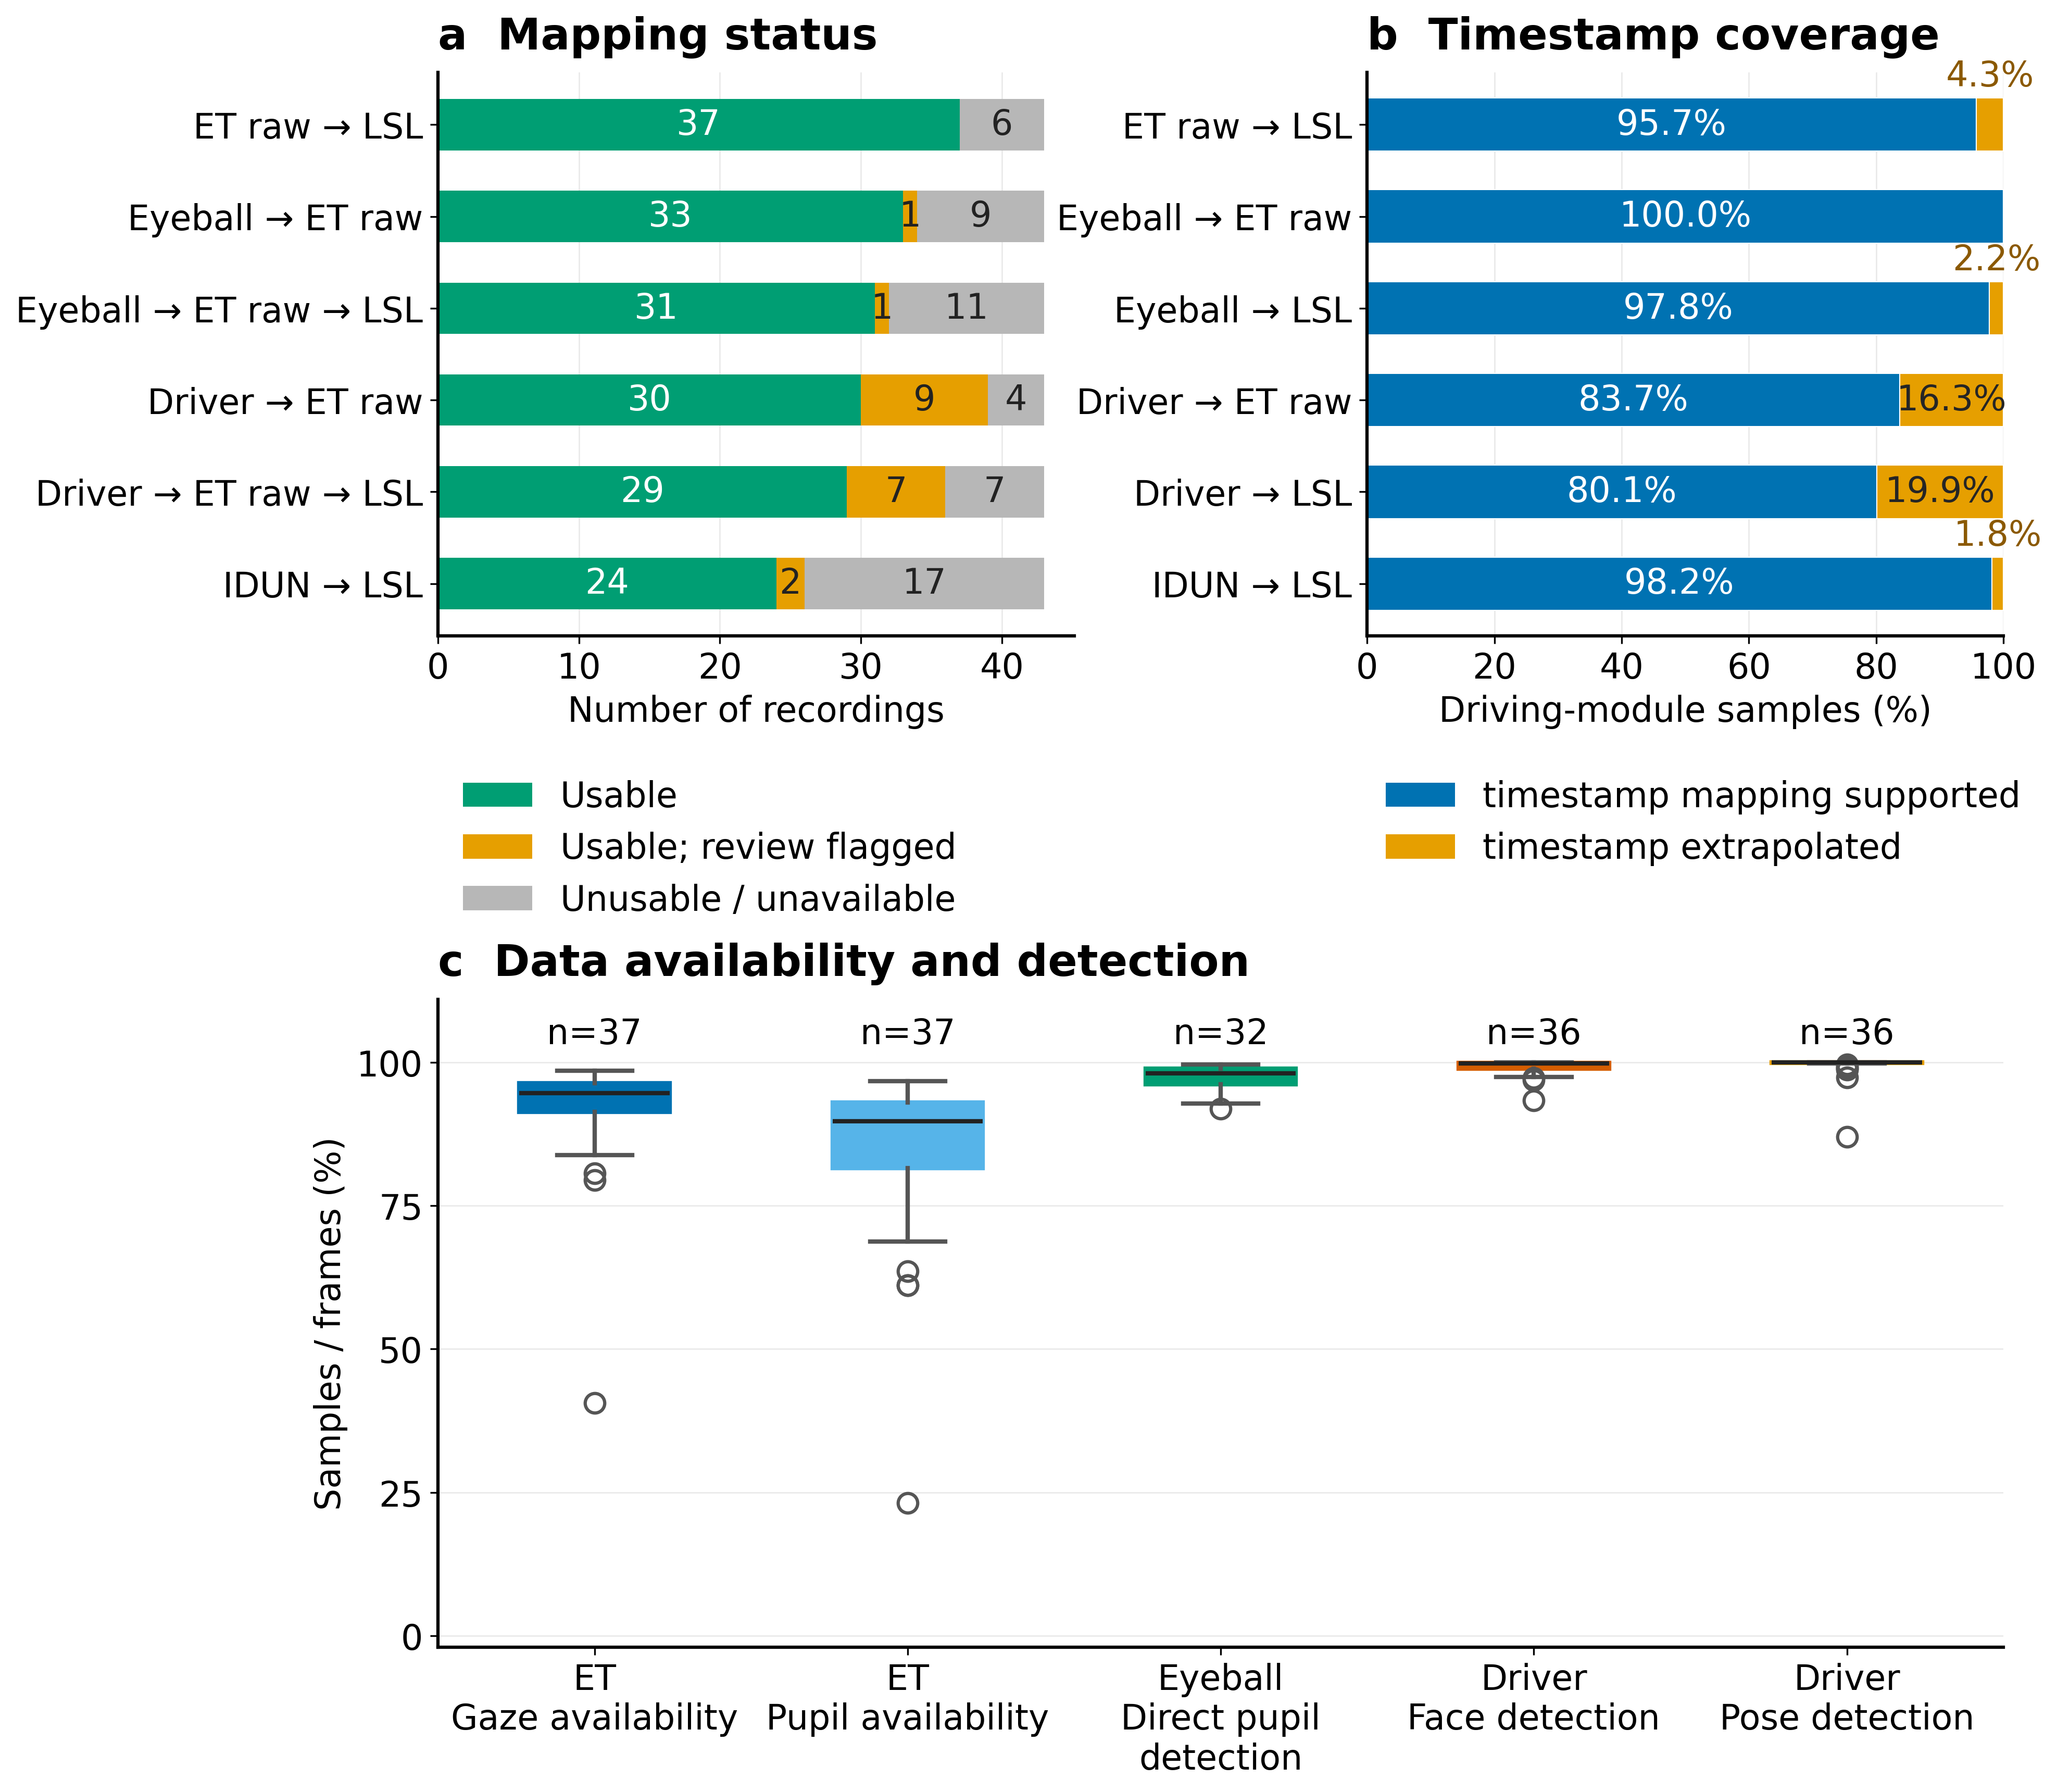

In [4]:
name = '12b_sync_quality_overview'
figure = plot_overview(RECORDS, COVERAGE, QUALITY)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if not OVERWRITE and any(OUTPUT_DIR.iterdir()):
    raise FileExistsError(f'Report output already exists: {OUTPUT_DIR}')
for extension in ('png', 'svg'):
    figure.savefig(OUTPUT_DIR / f'{name}.{extension}', dpi=300, bbox_inches='tight')
plt.close(figure)
display(Image(filename=str(OUTPUT_DIR / f'{name}.png'), width=1300))
